## 539 Integration Project: P2

In [5]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Nov 8: load U-Net, run on sample image, generate preliminary masks on 5 images

In [2]:
from brain_mri_data import make_loader, denormalize, LABELS, BrainMRIDataset

# Use Apple Silicon M1 GPU (mps) if available, otherwise cpu
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

unet = torch.hub.load('mateuszbuda/brain-segmentation-pytorch', 'unet',
                      in_channels=3, out_channels=1, init_features=32, pretrained=True)
unet = unet.to(device)
unet.eval()
print("Pretrained U-Net loaded!")

Using device: mps
Pretrained U-Net loaded!


Using cache found in /Users/anikalindell/.cache/torch/hub/mateuszbuda_brain-segmentation-pytorch_master


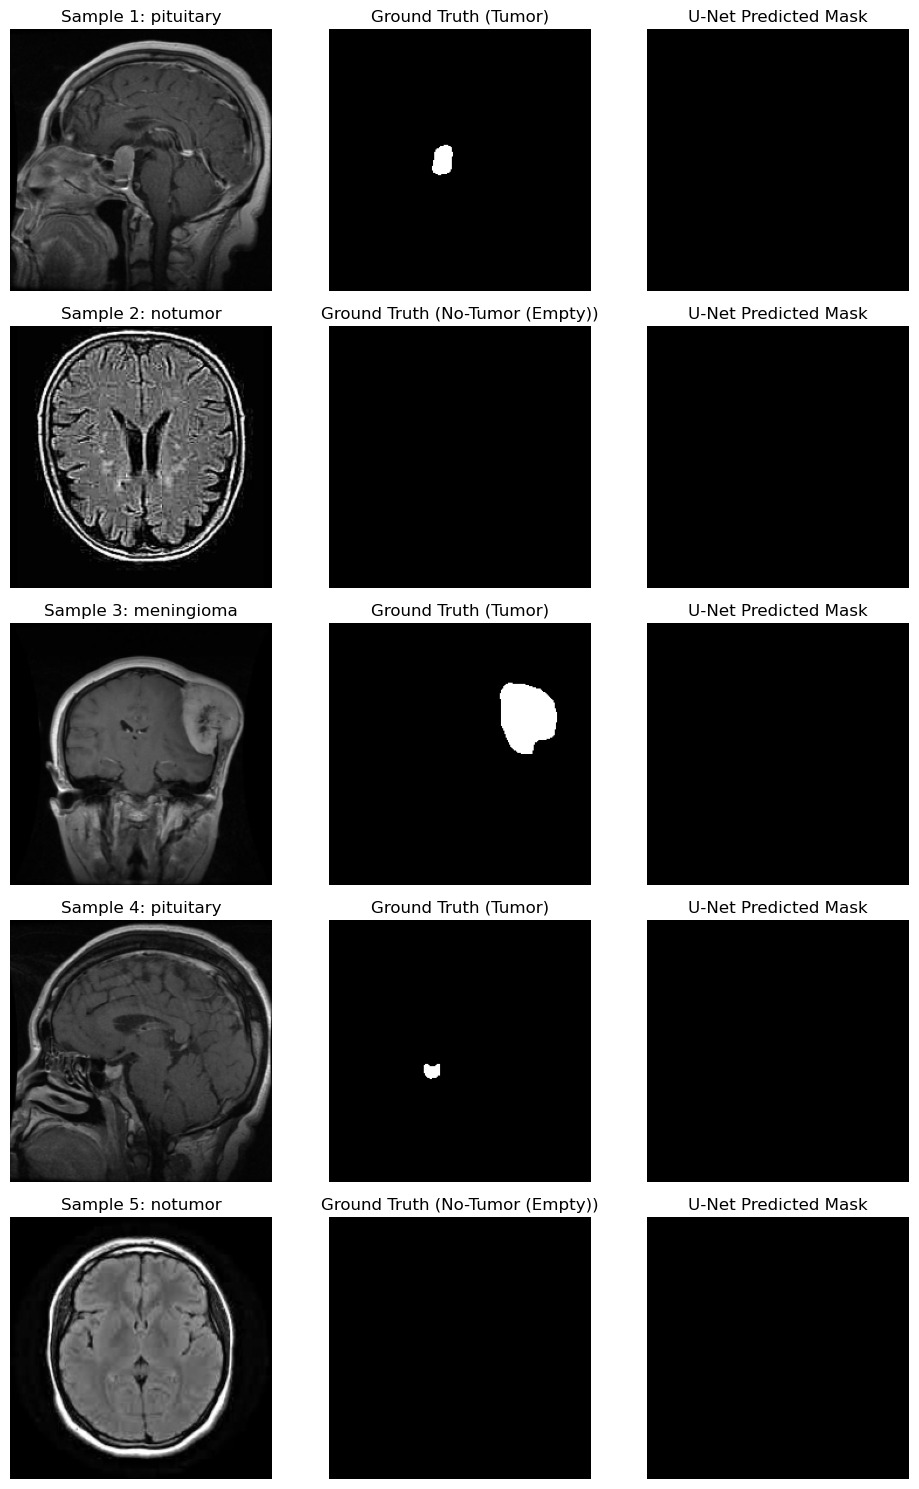

In [8]:
# normalize inputs for U-Net
def normalize_for_unet(images):
    # Undo ImageNet normalization to get back to [0, 1]
    mean = torch.tensor([0.485, 0.456, 0.406], device=images.device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=images.device).view(1, 3, 1, 1)
    raw = images * std + mean
    
    # Per-image Z-score normalize: (x - mean) / std
    img_mean = raw.mean(dim=(-2, -1), keepdim=True)
    img_std = raw.std(dim=(-2, -1), keepdim=True)
    return (raw - img_mean) / (img_std + 1e-8)


# get 5 samples from validation set for visualization
dev_loader = make_loader('dev', batch_size=5, shuffle=True)
batch = next(iter(dev_loader))

images = batch['image'].to(device)      # [5, 3, 224, 224]
true_masks = batch['mask'].to(device)   # [5, 1, 224, 224]
labels = batch['label']


# run U-Net on the 5 samples
unet_inputs = normalize_for_unet(images)

with torch.no_grad():
    preds = unet(unet_inputs)
    probs = torch.sigmoid(preds)
    pred_masks = (probs > 0.5).float()


fig, axes = plt.subplots(5, 3, figsize=(10, 15))

for i in range(5):
    cls_name = LABELS[labels[i]]
    
    # Col 1: Original MRI Slice
    mri_display = denormalize(images[i].cpu())
    axes[i, 0].imshow(mri_display, cmap='gray')
    axes[i, 0].set_title(f"Sample {i+1}: {cls_name}")
    axes[i, 0].axis('off')
    
    # Col 2: Ground Truth Mask
    axes[i, 1].imshow(true_masks[i, 0].cpu(), cmap='gray')
    has_m = "Tumor" if batch['has_mask'][i] else "No-Tumor (Empty)"
    axes[i, 1].set_title(f"Ground Truth ({has_m})")
    axes[i, 1].axis('off')
    
    # Col 3: U-Net Predicted Mask
    axes[i, 2].imshow(pred_masks[i, 0].cpu(), cmap='gray')
    axes[i, 2].set_title("U-Net Predicted Mask")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig("nov8_preliminary_5masks.png", dpi=200)
plt.show()

### Nov 10: 20 image visual inspection, Dice score computed

Evaluating 20 held-out images on off-the-shelf U-Net...


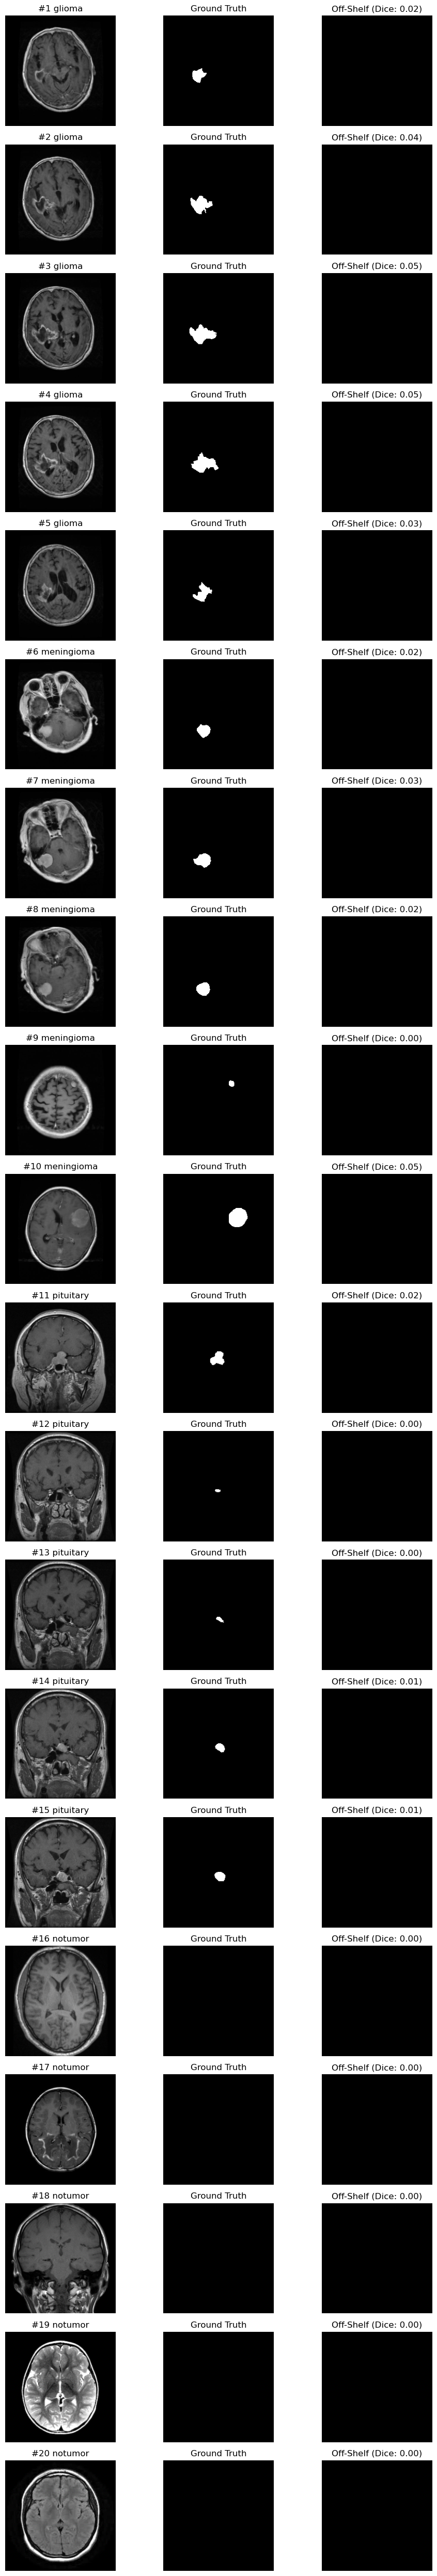


     NOV 10 MASK QUALITY EVALUATION TABLE
             dice  peak_prob
class                       
glioma      0.036      0.612
meningioma  0.024      0.592
notumor     0.000      0.502
pituitary   0.010      0.545

Overall Mean Dice: 0.018


In [9]:
# 20 images evaluation

def dice_score(pred_mask, true_mask, eps=1e-6):
    p = (pred_mask > 0.5).float().view(-1)
    t = (true_mask > 0.5).float().view(-1)
    if t.sum() == 0 and p.sum() == 0:
        return 1.0  # correctly predicted empty mask
    intersection = (p * t).sum()
    return ((2.0 * intersection + eps) / (p.sum() + t.sum() + eps)).item()

dev_dataset = BrainMRIDataset('dev')

# Select 5 samples for each of the 4 classes (20 total)
class_indices = {c: [] for c in LABELS}
for idx in range(len(dev_dataset)):
    raw_label = dev_dataset.df.iloc[idx]['label']
    label_name = LABELS[raw_label] if isinstance(raw_label, int) else raw_label
    if len(class_indices[label_name]) < 5:
        class_indices[label_name].append(idx)
    if all(len(v) == 5 for v in class_indices.values()):
        break

selected_indices = [idx for c in LABELS for idx in class_indices[c]]

results = []
fig, axes = plt.subplots(20, 3, figsize=(10, 50))

print("Evaluating 20 held-out images on off-the-shelf U-Net...")

for row, idx in enumerate(selected_indices):
    sample = dev_dataset[idx]
    img = sample['image'].unsqueeze(0).to(device)
    true_m = sample['mask'].unsqueeze(0).to(device)
    label_name = LABELS[sample['label']]
    
    # normalize inputs for U-Net
    unet_in = normalize_for_unet(img)
    with torch.no_grad():
        pred_raw = unet(unet_in)
        prob = torch.sigmoid(pred_raw)
        pred_m = (prob > 0.5).float()
    
    d_score = dice_score(pred_m, true_m)
    results.append({'class': label_name, 'dice': d_score, 'peak_prob': prob.max().item()})
    
    axes[row, 0].imshow(denormalize(img[0].cpu()), cmap='gray')
    axes[row, 0].set_title(f"#{row+1} {label_name}")
    axes[row, 0].axis('off')
    
    axes[row, 1].imshow(true_m[0, 0].cpu(), cmap='gray')
    axes[row, 1].set_title("Ground Truth")
    axes[row, 1].axis('off')
    
    axes[row, 2].imshow(pred_m[0, 0].cpu(), cmap='gray')
    axes[row, 2].set_title(f"Off-Shelf (Dice: {d_score:.2f})")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig("nov10_20image_mask_report.png", dpi=200)
plt.show()

# Summary Table
df_results = pd.DataFrame(results)
print("\n" + "="*50)
print("     NOV 10 MASK QUALITY EVALUATION TABLE")
print("="*50)
print(df_results.groupby('class')[['dice', 'peak_prob']].mean().round(3))
overall_dice = df_results['dice'].mean()
print(f"\nOverall Mean Dice: {overall_dice:.3f}")